In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [4]:
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


# Handling Missing Values

In [5]:
#Checking Missing Values
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [6]:
#For numerical values using mean
 # df["column_name"] = df["column_name"].fillna(df["column_name"].mean(),inplace=True)
# For numerical values using median
 # df["column_name"] = df["column_name"].fillna(df["column_name"].median(),inplace=True)

In [7]:
#For categorical columns
df['payment']=df['payment'].fillna(df['payment'].mode()[0],inplace=True)
df['pickup_zone']=df['pickup_zone'].fillna(df['pickup_zone'].mode()[0],inplace=True)
df['dropoff_zone']=df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0],inplace=True)
df['pickup_borough']=df['pickup_borough'].fillna(df['pickup_borough'].mode()[0],inplace=True)
df['dropoff_borough']=df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0],inplace=True)

In [8]:
# Removing null values
# df.dropna(subset=["critical_column"], inplace=True)

In [9]:
# Checking again for null values after filling
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

# Visualizations using Matplotlib/Pandas Plot:

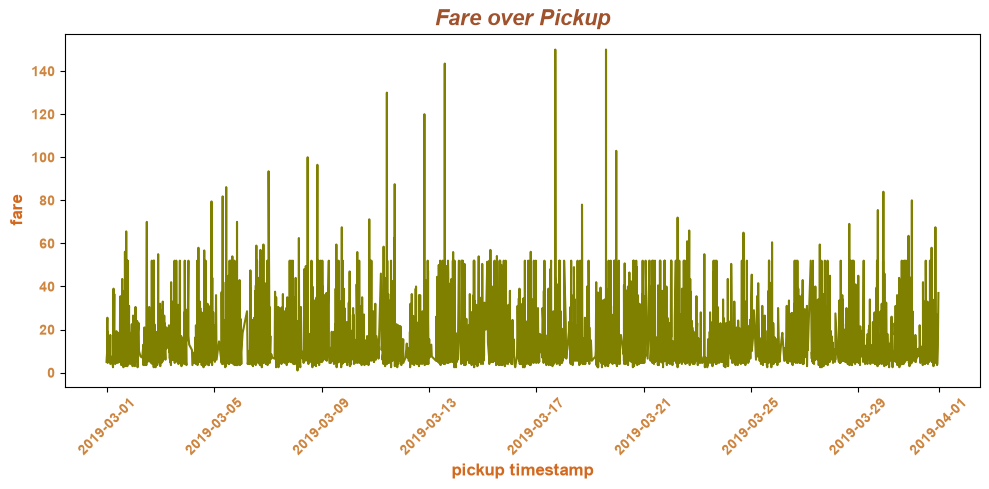

In [10]:
# Line Chart
df["pickup"]= pd.to_datetime(df["pickup"])
df= df.sort_values("pickup")
plt.figure(figsize=(10,5))
plt.plot(df["pickup"],df["fare"],color="olive")
plt.xlabel("pickup timestamp", color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.ylabel("fare",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.title("Fare over Pickup",color="sienna",fontsize=16,fontstyle='italic',fontweight="bold",fontname="Arial")
plt.xticks(rotation=45,color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.yticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.tight_layout()
plt.show()

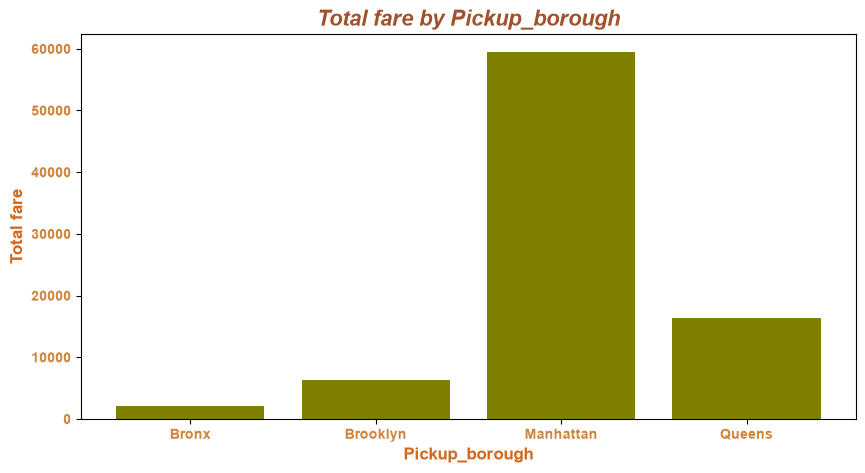

In [11]:
#Bar Chart
fare=df.groupby("pickup_borough")["fare"].sum()
plt.figure(figsize=(10,5))
plt.bar(fare.index,fare.values,color="olive")
plt.xlabel("Pickup_borough", color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.ylabel("Total fare",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.xticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.yticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.title("Total fare by Pickup_borough", color="sienna",fontsize=16,fontstyle='italic',fontweight="bold",fontname="Arial")
plt.show()

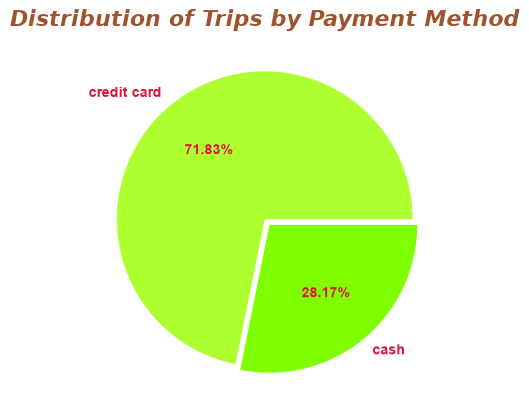

In [12]:
# Pie Chart
payment_count=df["payment"].value_counts()
plt.pie(payment_count.values,colors=["greenyellow","chartreuse"],labels=payment_count.index,explode=(0,0.05),autopct="%1.2f%%",
        textprops={"color": "crimson","fontname": "Arial","fontweight":"bold","fontsize":10})
plt.title("Distribution of Trips by Payment Method",
          fontsize=16, fontweight="bold", color="sienna",fontstyle="italic")
plt.show()

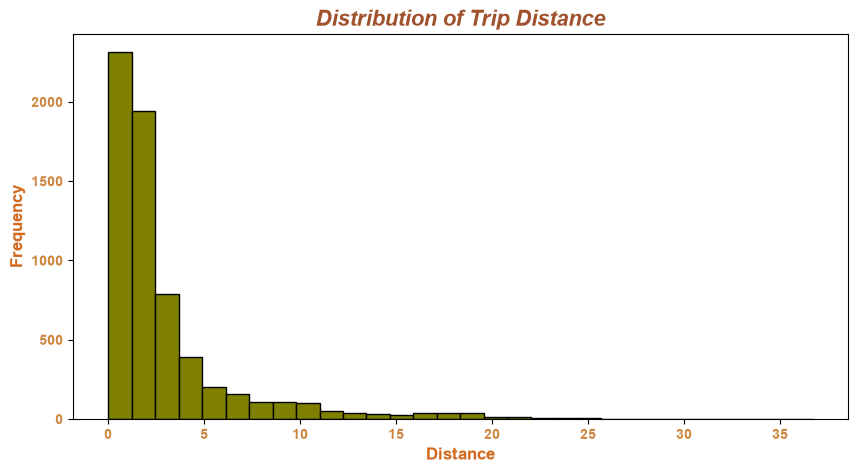

In [13]:
# Histogram
plt.figure(figsize=(10,5))
plt.hist(df["distance"],bins=30,color="olive",edgecolor="black")
plt.xlabel("Distance",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.ylabel("Frequency",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.title("Distribution of Trip Distance",color="sienna",fontsize=16,fontstyle='italic',fontweight="bold",fontname="Arial")
plt.xticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.yticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.show()
        

<Figure size 1000x500 with 0 Axes>

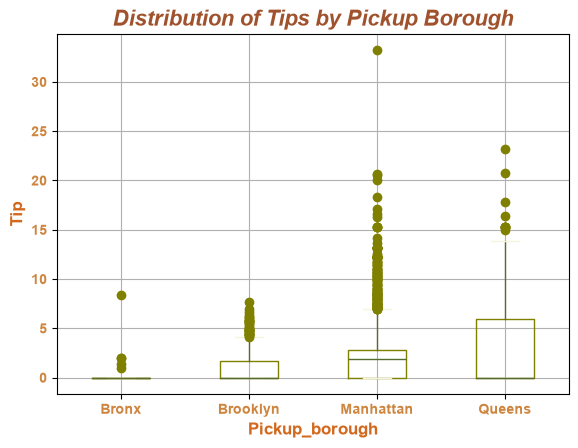

In [14]:
# Box plot
plt.figure(figsize=(10,5))
df.boxplot(column="tip",by="pickup_borough",boxprops={"color": "olive"},
    medianprops={"color": "darkolivegreen"},
    whiskerprops={"color": "darkolivegreen"},
    capprops={"color": "beige"},
    flierprops={"markerfacecolor": "olive",
                "markeredgecolor": "olive"})
plt.title("Distribution of Tips by Pickup Borough",color="sienna",fontsize=16,fontstyle='italic',fontweight="bold",fontname="Arial")
plt.xlabel("Pickup_borough",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.ylabel("Tip",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.xticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.yticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.suptitle("")
plt.show()

# Visualization using Seaborn

In [15]:
pickup_borough_counts=df["pickup_borough"].value_counts()
pickup_borough_counts


pickup_borough
Manhattan    5294
Queens        657
Brooklyn      383
Bronx          99
Name: count, dtype: int64

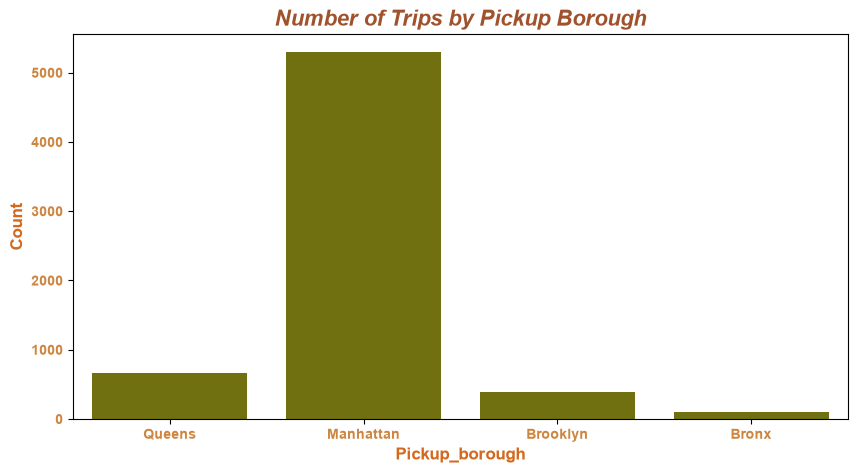

In [16]:
# Count Plot
plt.figure(figsize=(10,5))
sns.countplot(x="pickup_borough",data=df,color="olive")
plt.title("Number of Trips by Pickup Borough",color="sienna",fontsize=16,fontstyle='italic',fontweight="bold",fontname="Arial")
plt.xlabel("Pickup_borough",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.ylabel("Count",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.xticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.yticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.show()

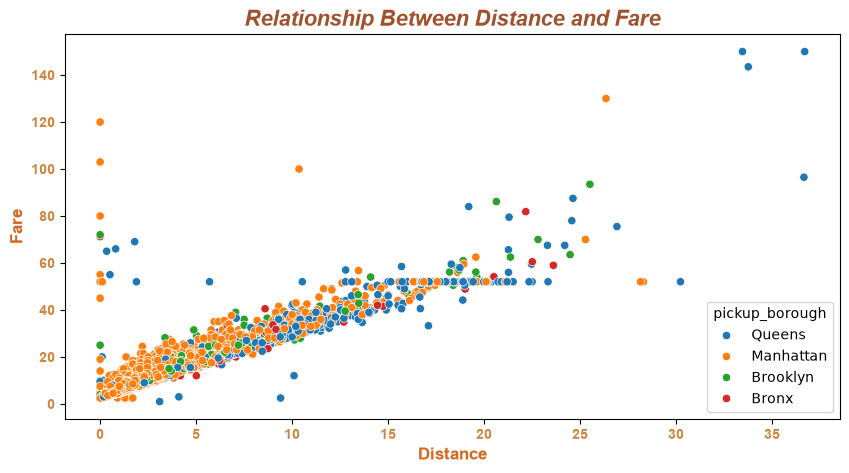

In [17]:
# Scatter Plot
plt.figure(figsize=(10,5))
sns.scatterplot(x=df["distance"],y=df["fare"],color="olive",hue=df["pickup_borough"])
plt.title("Relationship Between Distance and Fare",color="sienna",fontsize=16,fontstyle='italic',fontweight="bold",fontname="Arial")
plt.xlabel("Distance",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.ylabel("Fare",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.xticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.yticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.show()

In [18]:
numerical=df[["distance","fare","tip","tolls","total"]].select_dtypes("number")
numerical

,distance,fare,tip,tolls,total
6203,0.90,5.0,0.00,0.0,6.30
884,2.16,10.0,2.00,0.0,15.80
2882,7.35,22.5,1.00,0.0,27.30
4212,7.00,25.5,7.30,0.0,36.60
661,0.74,4.5,1.00,0.0,9.30
...,...,...,...,...,...
4220,1.00,7.5,0.70,0.0,12.00
2849,0.40,3.5,1.45,0.0,8.75
542,0.67,4.5,1.66,0.0,9.96
4067,3.03,11.5,3.82,0.0,19.12


In [19]:
correlation=numerical.corr()
correlation

,distance,fare,tip,tolls,total
distance,1.000000,0.920108,0.452589,0.635267,0.904676
fare,0.920108,1.000000,0.488612,0.609307,0.974358
tip,0.452589,0.488612,1.000000,0.413619,0.646186
tolls,0.635267,0.609307,0.413619,1.000000,0.683142
total,0.904676,0.974358,0.646186,0.683142,1.000000


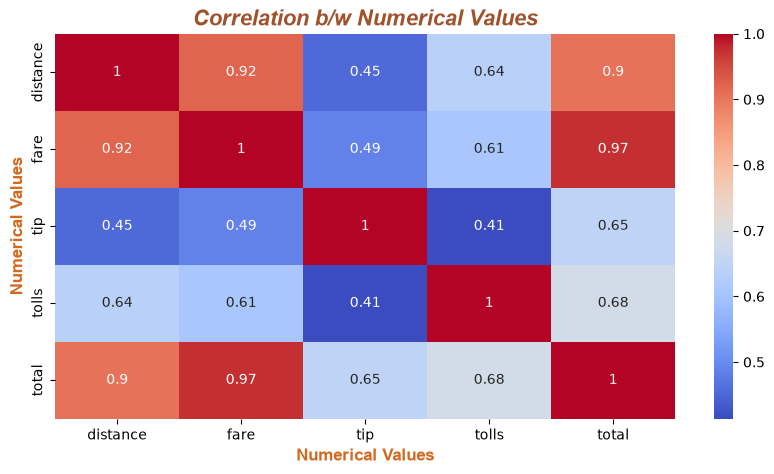

In [20]:
# Heat Map
plt.figure(figsize=(10,5))
sns.heatmap(correlation,annot=True,cmap="coolwarm")
plt.title("Correlation b/w Numerical Values",color="sienna",fontsize=16,fontstyle='italic',fontweight="bold",fontname="Arial")
plt.xlabel("Numerical Values",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.ylabel("Numerical Values",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.show()

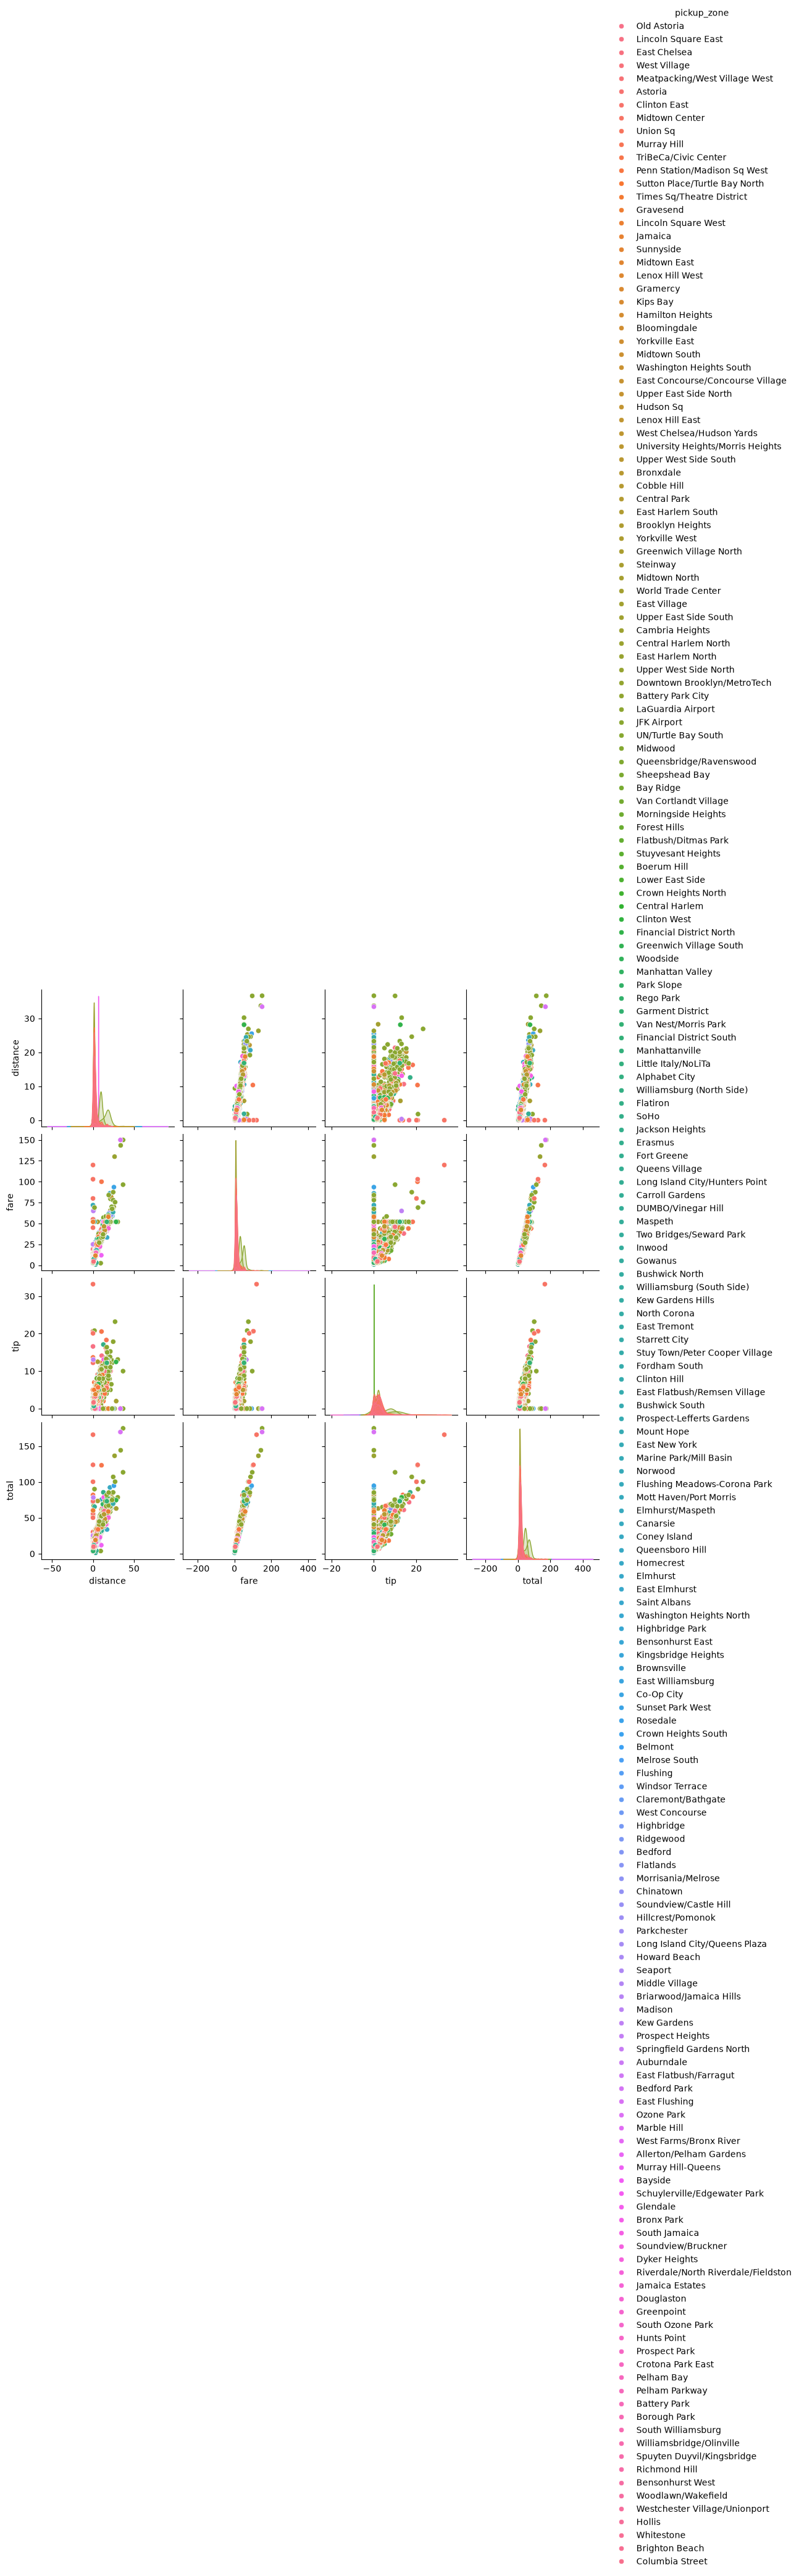

In [21]:
# Pair Plot
sns.pairplot(df, vars=["distance", "fare", "tip","total"], hue= "pickup_zone")
plt.show()

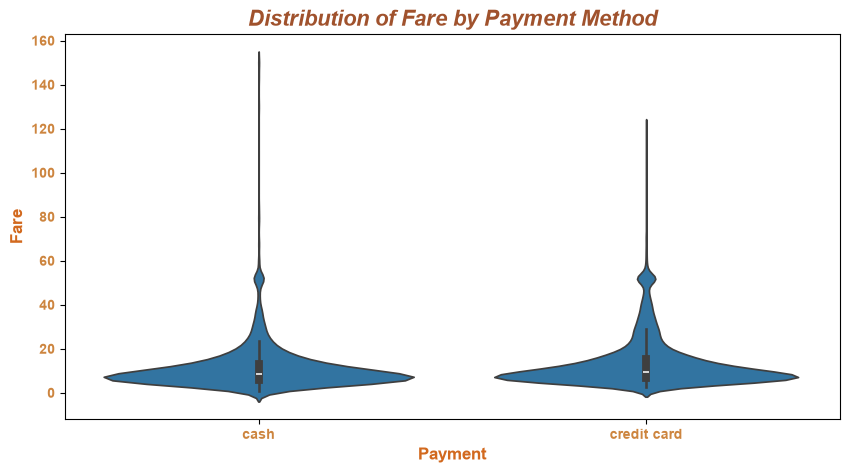

In [22]:
# Violin Plot
plt.figure(figsize=(10,5))
sns.violinplot(x="payment",y="fare",data=df)
plt.title("Distribution of Fare by Payment Method",color="sienna",fontsize=16,fontstyle='italic',fontweight="bold",fontname="Arial")
plt.xlabel("Payment",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.ylabel("Fare",color="chocolate",fontsize=12,fontweight="bold",fontname="Arial")
plt.xticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.yticks(color="peru",fontsize=10,fontweight="bold",fontname="Arial")
plt.show()